# Notebook 02 — Daily Revenue (Average per Day)

**Model**: `daily_revenue_predictor.pkl`  
**Algorithm**: Gradient Boosting Regressor  
**Target**: Average daily revenue for next month (Rs.)  
**Input Features**: Day-of-week + hour + rolling revenue averages

In [1]:
# What: Import required libraries for gradient boosting regression
# Why: GradientBoostingRegressor is strong for tabular data with sequential learning
# Method: sklearn GBR + standard data/viz stack
import pandas as pd
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import matplotlib.pyplot as plt
import joblib, os, warnings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid')

DATA_PATH    = '../data'
MODELS_PATH  = '../models'
RANDOM_STATE = 42
os.makedirs(MODELS_PATH, exist_ok=True)

# Department price proxy (Rs.) — consistent across all notebooks
DEPT_PRICE = {1:350,2:200,3:250,4:150,5:800,6:400,7:180,8:600,9:300,
              10:200,11:500,12:700,13:350,14:280,15:200,16:300,17:450,
              18:500,19:220,20:400,21:200}
print('Config loaded')

Config loaded


In [2]:
# What: Load orders and product data
# Why: Need order_dow, order_hour_of_day from orders; department from products
# Method: pandas read_csv for all required files
orders      = pd.read_csv(f'{DATA_PATH}/orders.csv')
op_train    = pd.read_csv(f'{DATA_PATH}/order_products__train.csv')
products    = pd.read_csv(f'{DATA_PATH}/products.csv')
departments = pd.read_csv(f'{DATA_PATH}/departments.csv')

print(f'Loaded — orders: {orders.shape}, op_train: {op_train.shape}')

Loaded — orders: (3421083, 7), op_train: (1384617, 4)


In [3]:
# What: Build item-level table with day, hour, and revenue columns
# Why: Need daily granularity features (order_dow, hour) to predict avg daily revenue
# Method: Merge chain op_train → products → departments → orders
products_dept = products.merge(departments, on='department_id', how='left')
order_items = op_train.merge(products_dept[['product_id','department_id']], on='product_id', how='left')
order_items = order_items.merge(
    orders[['order_id','user_id','order_number','order_dow','order_hour_of_day']],
    on='order_id', how='left'
)

order_items['price']   = order_items['department_id'].map(DEPT_PRICE).fillna(200)
order_items['revenue'] = order_items['price']

print('Items with day/hour/revenue:')
print(order_items[['order_id','order_dow','order_hour_of_day','revenue']].head())

Items with day/hour/revenue:
   order_id  order_dow  order_hour_of_day  revenue
0         1          4                 10      300
1         1          4                 10      300
2         1          4                 10      150
3         1          4                 10      150
4         1          4                 10      200


In [4]:
# What: Aggregate revenue to day-of-week × hour-of-day level
# Why: Model needs to predict avg daily revenue using time-of-day/week patterns
# Method: groupby (order_dow, order_hour_of_day) → sum revenue, count orders
dow_hourly = order_items.groupby(['order_dow','order_hour_of_day']).agg(
    total_revenue = ('revenue',  'sum'),
    order_count   = ('order_id', 'nunique')
).reset_index()

# Normalize — avg revenue per (dow, hour) slot
dow_hourly['avg_revenue'] = dow_hourly['total_revenue'] / dow_hourly['order_count'].clip(lower=1)
print(f'Day×Hour table: {dow_hourly.shape}')
print(dow_hourly.head(10).to_string(index=False))

Day×Hour table: (168, 5)
 order_dow  order_hour_of_day  total_revenue  order_count  avg_revenue
         0                  0         408390          149  2740.872483
         0                  1         285480          101  2826.534653
         0                  2         211090           77  2741.428571
         0                  3         139230           45  3094.000000
         0                  4          95090           32  2971.562500
         0                  5         163610           66  2478.939394
         0                  6         369190          116  3182.672414
         0                  7        1805270          567  3183.897707
         0                  8        4032470         1222  3299.893617
         0                  9        5522330         1774  3112.925592


In [5]:
# What: Build daily aggregate table (per simulated day-of-week)
# Why: Model target is avg daily revenue — aggregate at daily level
# Method: groupby order_dow, compute mean and std revenue per day
daily = order_items.groupby('order_dow').agg(
    daily_total_revenue = ('revenue',    'sum'),
    daily_order_count   = ('order_id',   'nunique'),
    daily_item_count    = ('product_id', 'count'),
    avg_hour            = ('order_hour_of_day', 'mean'),
    peak_hour           = ('order_hour_of_day', lambda x: x.mode()[0])
).reset_index()

daily['avg_daily_revenue']   = daily['daily_total_revenue'] / daily['daily_order_count']
daily['items_per_order']     = daily['daily_item_count']    / daily['daily_order_count']

# One-hot encode day of week — 7 binary columns
dow_dummies = pd.get_dummies(daily['order_dow'], prefix='dow')
daily = pd.concat([daily, dow_dummies], axis=1)

print('Daily feature table:')
print(daily[['order_dow','avg_daily_revenue','avg_hour','items_per_order']].to_string(index=False))

Daily feature table:
 order_dow  avg_daily_revenue  avg_hour  items_per_order
         0        3083.686874 13.583302        11.797779
         1        2739.043310 13.393756        10.470618
         2        2633.634220 13.705646         9.961040
         3        2619.341493 13.637106         9.841334
         4        2592.220064 13.665406         9.742528
         5        2705.712973 13.385009        10.163737
         6        2914.618803 13.706328        10.966563


In [6]:
# What: Create sliding window features using data from all monthly order chunks
# Why: 7 rows (one per DOW) is too few — expand dataset using monthly simulated slices
# Method: Repeat feature engineering per simulated month_num to get 200+ training rows
order_items['month_num'] = np.ceil(order_items['order_number'] / 3).astype(int)

month_daily = order_items.groupby(['month_num','order_dow']).agg(
    monthly_daily_revenue = ('revenue',    'sum'),
    monthly_order_count   = ('order_id',   'nunique'),
    monthly_item_count    = ('product_id', 'count'),
    avg_reorder           = ('reordered',  'mean'),
    avg_hour              = ('order_hour_of_day', 'mean')
).reset_index()

month_daily['avg_daily_revenue'] = month_daily['monthly_daily_revenue'] / month_daily['monthly_order_count'].clip(lower=1)
month_daily['items_per_order']   = month_daily['monthly_item_count'] / month_daily['monthly_order_count'].clip(lower=1)

print(f'Month × Day training table: {month_daily.shape}')
print(month_daily.head())

Month × Day training table: (231, 9)
   month_num  order_dow  monthly_daily_revenue  monthly_order_count  \
0          2          0               22599010                 7702   
1          2          1               15985710                 6062   
2          2          2               12534520                 4939   
3          2          3               11934470                 4647   
4          2          4               11063190                 4512   

   monthly_item_count  avg_reorder   avg_hour  avg_daily_revenue  \
0               85731     0.448787  13.719996        2934.174240   
1               60584     0.453437  13.604169        2637.035632   
2               47122     0.441620  13.941492        2537.865965   
3               44577     0.441999  13.798618        2568.209598   
4               40883     0.422621  13.809432        2451.948138   

   items_per_order  
0        11.131005  
1         9.994061  
2         9.540798  
3         9.592640  
4         9.060949  


In [7]:
# What: Add lag features — previous month same-DOW revenue
# Why: Same-day-last-month is a strong predictor of today's revenue
# Method: Sort by month_num + order_dow, shift by 7 (one week back)
month_daily.sort_values(['order_dow','month_num'], inplace=True)
month_daily['prev_same_dow_revenue'] = month_daily.groupby('order_dow')['avg_daily_revenue'].shift(1)
month_daily['revenue_growth_dow']    = month_daily.groupby('order_dow')['avg_daily_revenue'].pct_change()
month_daily.dropna(inplace=True)

print(f'After lag engineering: {month_daily.shape}')

After lag engineering: (224, 11)


In [8]:
# What: Prepare X and y for Gradient Boosting training
# Why: Separate feature columns from the target avg_daily_revenue
# Method: Select numeric features relevant to daily revenue prediction
FEATURES = ['order_dow','monthly_order_count','monthly_item_count','avg_reorder',
            'avg_hour','items_per_order','prev_same_dow_revenue','revenue_growth_dow']

X = month_daily[FEATURES].values
y = month_daily['avg_daily_revenue'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape} | Test: {X_test.shape}')

Train: (179, 8) | Test: (45, 8)


In [9]:
# What: Train Gradient Boosting Regressor for daily revenue average
# Why: GBR builds sequential trees that correct previous errors — high accuracy on tabular data
# Method: 300 estimators, learning_rate=0.05 for stable convergence, max_depth=4
model = GradientBoostingRegressor(
    n_estimators   = 300,
    learning_rate  = 0.05,   # small step size prevents overfitting
    max_depth      = 4,      # moderate tree depth
    min_samples_leaf = 5,
    subsample      = 0.8,    # stochastic gradient boosting for better generalization
    random_state   = RANDOM_STATE
)
model.fit(X_train, y_train)
print('Training complete')

Training complete


In [10]:
# What: Evaluate model performance on test set
# Why: Validate that model generalizes to unseen day-revenue combinations
# Method: RMSE (in Rs.), MAE, R² — compare to baseline mean prediction
y_pred = model.predict(X_test)

rmse     = np.sqrt(mean_squared_error(y_test, y_pred))
mae      = mean_absolute_error(y_test, y_pred)
r2       = r2_score(y_test, y_pred)
baseline = np.sqrt(mean_squared_error(y_test, np.full_like(y_test, y_train.mean())))

print('=== Model Performance ===')
print(f'RMSE     : Rs. {rmse:>10,.2f}')
print(f'Baseline : Rs. {baseline:>10,.2f}   (mean prediction)')
print(f'MAE      : Rs. {mae:>10,.2f}')
print(f'R²       : {r2:>14.4f}')

=== Model Performance ===
RMSE     : Rs.      94.80
Baseline : Rs.     374.38   (mean prediction)
MAE      : Rs.      61.11
R²       :         0.9353


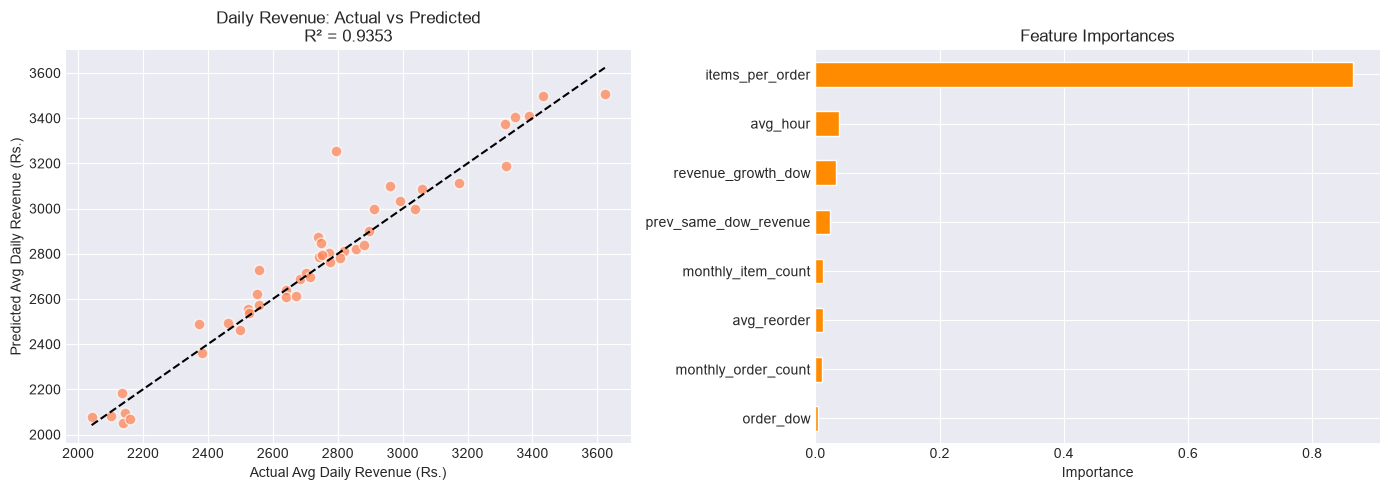

Plot saved


In [12]:
# What: Plot predicted vs actual daily revenues and feature importances
# Why: Visual check of model fit quality and what drives daily revenue
# Method: Two-panel matplotlib plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(y_test, y_pred, color='coral', alpha=0.7, edgecolors='white', s=60)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, 'k--', lw=1.5)
axes[0].set_xlabel('Actual Avg Daily Revenue (Rs.)')
axes[0].set_ylabel('Predicted Avg Daily Revenue (Rs.)')
axes[0].set_title(f'Daily Revenue: Actual vs Predicted\nR² = {r2:.4f}')

# Feature importances
fi = pd.Series(model.feature_importances_, index=FEATURES).sort_values(ascending=True)
fi.plot(kind='barh', ax=axes[1], color='darkorange', edgecolor='white')
axes[1].set_title('Feature Importances')
axes[1].set_xlabel('Importance')

plt.tight_layout()
plt.savefig(f'{MODELS_PATH}/chart_daily_revenue_model.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved')

In [13]:
# What: Save trained Gradient Boosting model as .pkl
# Why: API endpoint loads this model to return avg daily revenue prediction
# Method: joblib.dump — efficient serialization for sklearn estimators
joblib.dump(model, f'{MODELS_PATH}/daily_revenue_predictor.pkl')
print('Saved: models/daily_revenue_predictor.pkl')
print(f'   Size: {os.path.getsize(f"{MODELS_PATH}/daily_revenue_predictor.pkl") / 1024:.1f} KB')

Saved: models/daily_revenue_predictor.pkl
   Size: 356.4 KB


In [14]:
# What: Demonstrate inference — predict avg daily revenue per day of week
# Why: Show how the API will use this model to produce the dashboard value
# Method: Create 7 feature rows (one per DOW), predict, show per-day summary
loaded = joblib.load(f'{MODELS_PATH}/daily_revenue_predictor.pkl')
dow_names = ['Sunday','Monday','Tuesday','Wednesday','Thursday','Friday','Saturday']

# Use mean values for other features, vary only order_dow
last_month_data = month_daily[FEATURES].copy()
last_vals = last_month_data.groupby(last_month_data.index % 7).mean()

for dow_i, day_name in enumerate(dow_names):
    sample = last_vals.iloc[[min(dow_i, len(last_vals)-1)]].values
    sample[0][0] = dow_i  # override order_dow
    pred = loaded.predict(sample)[0]
    print(f'{day_name:12s}: Rs. {pred:,.2f}')

Sunday      : Rs. 3,147.47
Monday      : Rs. 2,784.43
Tuesday     : Rs. 2,700.02
Wednesday   : Rs. 2,602.72
Thursday    : Rs. 2,614.55
Friday      : Rs. 2,732.82
Saturday    : Rs. 3,040.72
